# Tiles v1: exclude ink tiles, keep tumor and benign tiles

Starts from the EDA v4 tile table (`eda_v4_outputs/{pt}_tiles.csv`), where ink was detected on a small thumbnail.
At that scale one tile is only about 7 pixels, so small ink marks can be missed. This notebook:

1. Rechecks every tissue tile for ink at higher resolution (pyramid level 1, about 1.4 µm/px).
2. Labels each tile:
   * `tumor`: inside an ink region
   * `benign_presumed`: outside all ink regions and at least `BENIGN_MARGIN_UM` away from them
   * `excluded_ink`: touches ink (thumbnail check or high-resolution check)
   * `excluded_buffer`: outside regions but too close to them to call benign
   * `uncertain`: inside a region flagged as ambiguous
   * `pending`: slide whose tumor location still needs the lab (pt104)
   * `excluded_unreadable`: the stored image data for this tile is damaged at every level we tried
3. Shows sample tiles from each group at full resolution, and a map of the labels per slide.

Unmarked tissue is not confirmed benign: the pathologist only marked tumors on this section. The margin keeps "benign" tiles away from marked tumor edges.

**Run order:** install cell, restart the session, then run from the mount cell. Needs EDA v4 outputs.

## 0. Install, then restart the session

In [1]:
!pip install -q "imagecodecs[all]" tifffile scikit-image

In [2]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Not in Colab; skipping Drive mount.')

Mounted at /content/drive


## 1. Setup

In [3]:
import os, json, time, threading
import numpy as np
import pandas as pd
import tifffile
import imagecodecs
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from PIL import Image
from functools import lru_cache
from scipy import ndimage as ndi
from skimage.color import rgb2hsv
from IPython.display import display

DATA_DIR = '/content/drive/MyDrive/spring/capstone/data'
EDA_DIR  = os.path.join(DATA_DIR, 'eda_v4_outputs')
OUT_DIR  = os.path.join(DATA_DIR, 'tiles_v1')
assert os.path.isdir(EDA_DIR), f'Run the EDA v4 notebook first ({EDA_DIR} not found)'
os.makedirs(os.path.join(OUT_DIR, 'figures'), exist_ok=True)

PATIENTS  = ['pt104', 'pt107', 'pt109', 'pt111', 'pt112']
TIF_FILES = {pt: os.path.join(DATA_DIR, f'{pt}.ome.tif') for pt in PATIENTS}

TILE_UM          = 128      # same tiles as the EDA
MIN_TISSUE       = 0.5      # tiles with less tissue are dropped
CHECK_LEVEL      = 1        # pyramid level for the high-resolution ink check (1 = 4x smaller than full)
INK_H, INK_S     = (0.50, 0.70), 0.50   # same ink color rule as the EDA
INK_FRAC_THRESH  = 0.002    # tile counts as touching ink if more than 0.2% of its pixels are ink
BENIGN_MARGIN_UM = 1000     # benign tiles must be at least 1 mm from any ink region
PENDING = {'pt104': 'lab to confirm which loop is tumor'}

LABELS = ['tumor', 'benign_presumed', 'excluded_ink', 'excluded_buffer', 'uncertain', 'pending', 'excluded_unreadable']
COLORS = ['#d62728', '#2ca02c', '#111111', '#cccccc', '#ff9f1c', '#ff9f1c', '#7b3fbf']

def save_fig(name):
    plt.savefig(os.path.join(OUT_DIR, 'figures', f'{name}.png'), dpi=150, bbox_inches='tight')

SLIDES = [pt for pt in PATIENTS if os.path.exists(TIF_FILES[pt]) and os.path.exists(os.path.join(EDA_DIR, f'{pt}_tiles.csv'))]
print('Slides with a tile table:', SLIDES)
for pt in PATIENTS:
    if pt not in SLIDES:
        print(f'  {pt}: skipped (no slide, unusable slide, or no tile table)')

Slides with a tile table: ['pt104', 'pt109']
  pt107: skipped (no slide, unusable slide, or no tile table)
  pt111: skipped (no slide, unusable slide, or no tile table)
  pt112: skipped (no slide, unusable slide, or no tile table)


## 2. Slide reader
Reads any rectangle at a chosen pyramid level by decoding only the stored tiles it overlaps.
Decodes JPEG tiles directly, so it does not depend on tifffile finding imagecodecs (the cause of the stuck thumbnails before).

In [4]:
def to_rgb(arr):
    arr = np.squeeze(arr)
    if arr.ndim == 2: arr = np.stack([arr] * 3, -1)
    if arr.ndim == 3 and arr.shape[0] in (3, 4) and arr.shape[-1] not in (3, 4):
        arr = np.moveaxis(arr, 0, -1)
    return np.ascontiguousarray(arr[..., :3]).astype(np.uint8)

class SlideReader:
    def __init__(self, path, level=0, cache_tiles=1024):
        self.tif = tifffile.TiffFile(path)
        levels = self.tif.series[0].levels
        self.level = min(level, len(levels) - 1)
        pg = levels[self.level].keyframe
        self.downsample = levels[0].keyframe.imagewidth / pg.imagewidth
        self.pg, self.th, self.tw = pg, pg.tilelength, pg.tilewidth
        self.H, self.W = pg.imagelength, pg.imagewidth
        self.ny, self.nx = -(-self.H // self.th), -(-self.W // self.tw)
        self.offsets, self.counts = pg.dataoffsets, pg.databytecounts
        self.lock = threading.Lock()
        self.n_bad, self.last_bad = 0, False
        self.tile = lru_cache(maxsize=cache_tiles)(self._read_tile)

    def _read_tile(self, ty, tx):
        i = ty * self.nx + tx
        blank = np.full((self.th, self.tw, 3), 255, np.uint8)
        if i >= len(self.offsets) or self.counts[i] == 0: return blank
        with self.lock:
            self.tif.filehandle.seek(self.offsets[i])
            buf = self.tif.filehandle.read(self.counts[i])
        try:
            t = imagecodecs.jpeg_decode(buf, tables=self.pg.jpegtables) if self.pg.jpegtables else imagecodecs.jpeg_decode(buf)
        except Exception:
            self.n_bad += 1          # damaged tile data (seen in pt104 and pt107)
            return None
        t = to_rgb(t)
        if t.shape[:2] != (self.th, self.tw):
            blank[:t.shape[0], :t.shape[1]] = t[:self.th, :self.tw]; t = blank
        return t

    def read_region(self, x0, y0, w, h):
        # x0, y0, w, h in this level's pixels
        out = np.full((h, w, 3), 255, np.uint8)
        self.last_bad = False
        for ty in range(max(y0 // self.th, 0), min((y0 + h - 1) // self.th, self.ny - 1) + 1):
            for tx in range(max(x0 // self.tw, 0), min((x0 + w - 1) // self.tw, self.nx - 1) + 1):
                t = self.tile(ty, tx)
                if t is None:
                    self.last_bad = True; continue
                ys0, ys1 = max(y0, ty * self.th), min(y0 + h, (ty + 1) * self.th)
                xs0, xs1 = max(x0, tx * self.tw), min(x0 + w, (tx + 1) * self.tw)
                out[ys0 - y0:ys1 - y0, xs0 - x0:xs1 - x0] = t[ys0 - ty * self.th:ys1 - ty * self.th,
                                                               xs0 - tx * self.tw:xs1 - tx * self.tw]
        return out

    def read_level0_box(self, x0, y0, size0):
        # read a square given in full-resolution coordinates, at this reader's level
        d = self.downsample
        return self.read_region(int(x0 / d), int(y0 / d), max(1, int(round(size0 / d))), max(1, int(round(size0 / d))))

    def close(self):
        self.tif.close()

def ink_fraction(img):
    hsv = rgb2hsv(img)
    m = (hsv[..., 0] >= INK_H[0]) & (hsv[..., 0] <= INK_H[1]) & (hsv[..., 1] >= INK_S) & (hsv[..., 2] > 0.15)
    return float(m.mean())
print('Reader ready.')

Reader ready.


## 3. High-resolution ink check and tile labels
Saves `tiles_v1/{pt}_tile_labels.csv`: one row per tissue tile with full-resolution coordinates, its label,
the ink fraction at level 1, and the distance to the nearest ink region.

In [5]:
def label_slide(pt):
    t = pd.read_csv(os.path.join(EDA_DIR, f'{pt}_tiles.csv'))
    regs_path = os.path.join(EDA_DIR, f'{pt}_regions.csv')
    regs = pd.read_csv(regs_path) if os.path.exists(regs_path) and os.path.getsize(regs_path) > 1 else pd.DataFrame()
    flagged = set()
    if len(regs) and 'flags' in regs:
        flagged = set(regs.loc[regs['flags'].fillna('').astype(str).str.len() > 0, 'region_id'].astype(int))

    # distance from every tile to the nearest ink-region tile, on the tile grid
    gx = np.round(t.x0 / t.tile_px).astype(int).values
    gy = np.round(t.y0 / t.tile_px).astype(int).values
    in_reg = t.region_id.values >= 0
    grid = np.zeros((gy.max() + 1, gx.max() + 1), bool)
    grid[gy[in_reg], gx[in_reg]] = True
    dist_tiles = ndi.distance_transform_edt(~grid) if grid.any() else np.full(grid.shape, np.inf)
    t['dist_to_region_um'] = (dist_tiles[gy, gx] * TILE_UM).round(0)
    t['gx'], t['gy'] = gx, gy

    t = t[t.tissue_frac >= MIN_TISSUE].reset_index(drop=True)

    # high-resolution ink check
    reader = SlideReader(TIF_FILES[pt], level=CHECK_LEVEL)
    reader0 = SlideReader(TIF_FILES[pt], level=0) if reader.level != 0 else None   # fallback for damaged tiles
    print(f'{pt}: checking {len(t)} tissue tiles at level {reader.level} (×{reader.downsample:.0f} smaller than full)')
    fr, t0 = np.zeros(len(t)), time.time()
    n_bad_check, n_recovered = 0, 0
    for i, r in enumerate(t.itertuples()):
        img = reader.read_level0_box(int(r.x0), int(r.y0), int(r.tile_px))
        bad = reader.last_bad
        if bad:
            n_bad_check += 1
            if reader0 is not None:
                img = reader0.read_level0_box(int(r.x0), int(r.y0), int(r.tile_px))
                bad = reader0.last_bad
                n_recovered += int(not bad)
        fr[i] = np.nan if bad else ink_fraction(img)
        if i % 10000 == 0 and i:
            print(f'   {i}/{len(t)} ({i / (time.time() - t0):.0f} tiles/s)')
    print(f'   damaged at level {reader.level}: {n_bad_check} tiles; recovered from full resolution: {n_recovered}; '
          f'unreadable: {int(np.isnan(fr).sum())}')
    UNREADABLE[pt] = {'damaged_at_check_level': n_bad_check, 'recovered_full_res': n_recovered,
                      'unreadable': int(np.isnan(fr).sum())}
    reader.close()
    if reader0 is not None: reader0.close()
    t['ink_frac_hires'] = fr.round(4)
    t['ink_thumb'] = t.touches_ink.astype(bool)
    t['ink_hires'] = t.ink_frac_hires > INK_FRAC_THRESH

    lab = np.full(len(t), 'benign_presumed', dtype=object)
    lab[t.dist_to_region_um.values < BENIGN_MARGIN_UM] = 'excluded_buffer'
    lab[t.region_id.values >= 0] = 'tumor'
    lab[t.region_id.isin(flagged).values] = 'uncertain'
    if pt in PENDING:
        lab[:] = 'pending'
    lab[(t.ink_thumb | t.ink_hires).values] = 'excluded_ink'
    lab[np.isnan(fr)] = 'excluded_unreadable'
    t['label'] = lab
    cols = ['x0', 'y0', 'tile_px', 'gx', 'gy', 'tissue_frac', 'region_id', 'dist_to_region_um',
            'ink_thumb', 'ink_frac_hires', 'ink_hires', 'label']
    t[cols].to_csv(os.path.join(OUT_DIR, f'{pt}_tile_labels.csv'), index=False)
    return t[cols]

UNREADABLE = {}
labels = {pt: label_slide(pt) for pt in SLIDES}
display(pd.DataFrame(UNREADABLE).T)

pt104: checking 42855 tissue tiles at level 1 (×4 smaller than full)
   10000/42855 (269 tiles/s)
   20000/42855 (282 tiles/s)
   30000/42855 (292 tiles/s)
   40000/42855 (286 tiles/s)
   damaged at level 1: 6 tiles; recovered from full resolution: 6; unreadable: 0
pt109: checking 29637 tissue tiles at level 1 (×4 smaller than full)
   10000/29637 (298 tiles/s)
   20000/29637 (300 tiles/s)
   damaged at level 1: 32 tiles; recovered from full resolution: 32; unreadable: 0


,damaged_at_check_level,recovered_full_res,unreadable
pt104,6,6,0
pt109,32,32,0


## 4. Summary
* `ink_thumb_only` / `ink_hires_only`: tiles that only one of the two checks caught.
  A large `ink_hires_only` count means the thumbnail check was missing ink; the QA grid below shows whether those catches are real.

In [6]:
rows = []
for pt, t in labels.items():
    r = {'patient': pt, 'tissue_tiles': len(t)}
    r.update(t.label.value_counts().reindex(LABELS, fill_value=0).to_dict())
    r['ink_thumb_only'] = int((t.ink_thumb & ~t.ink_hires).sum())
    r['ink_hires_only'] = int((~t.ink_thumb & t.ink_hires).sum())
    r['ink_both'] = int((t.ink_thumb & t.ink_hires).sum())
    r['pct_lost_to_ink'] = round(100 * (t.label == 'excluded_ink').mean(), 1)
    rows.append(r)
summary = pd.DataFrame(rows).set_index('patient')
display(summary)
summary.to_csv(os.path.join(OUT_DIR, 'summary.csv'))

,tissue_tiles,tumor,benign_presumed,excluded_ink,excluded_buffer,uncertain,pending,excluded_unreadable,ink_thumb_only,ink_hires_only,ink_both,pct_lost_to_ink
patient,,,,,,,,,,,,
pt104,42855,0,0,3699,0,0,39156,0,475,411,2813,8.6
pt109,29637,579,26555,807,1696,0,0,0,73,322,412,2.7


## 5. Visual check at full resolution
Rows: tumor tiles, benign tiles, excluded tiles caught by both checks, and tiles caught **only** by the high-resolution check.
Tumor and benign rows should contain no ink. The last row tells us whether the extra catches are real ink or false alarms.

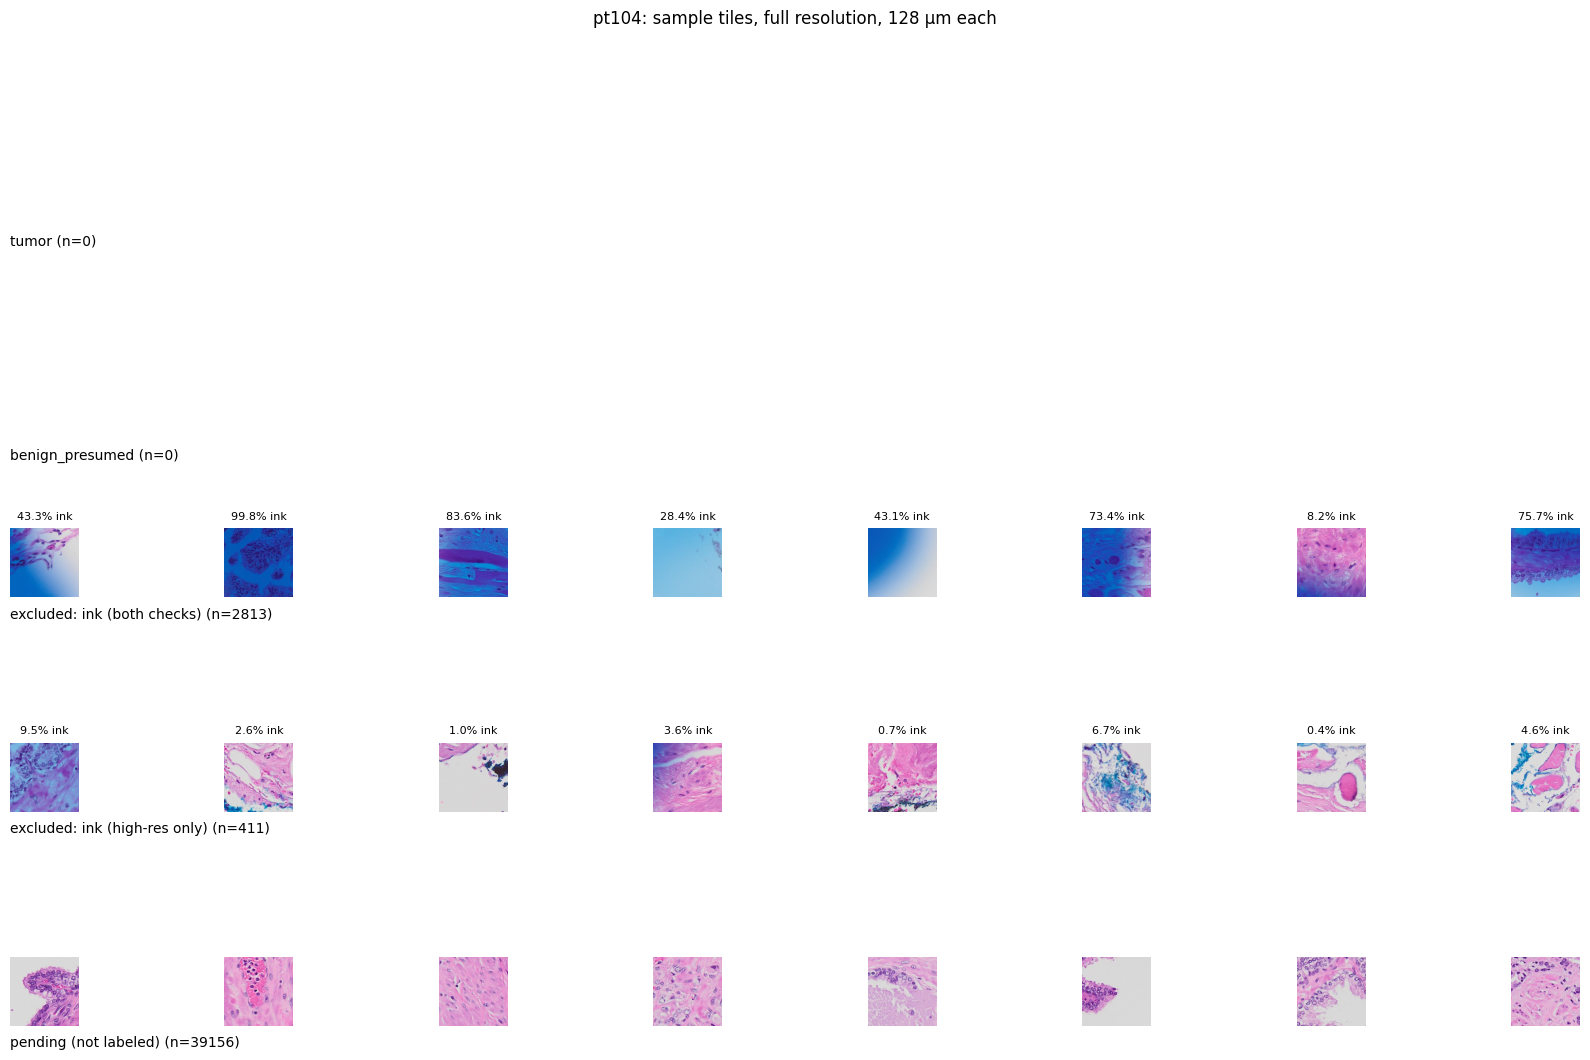

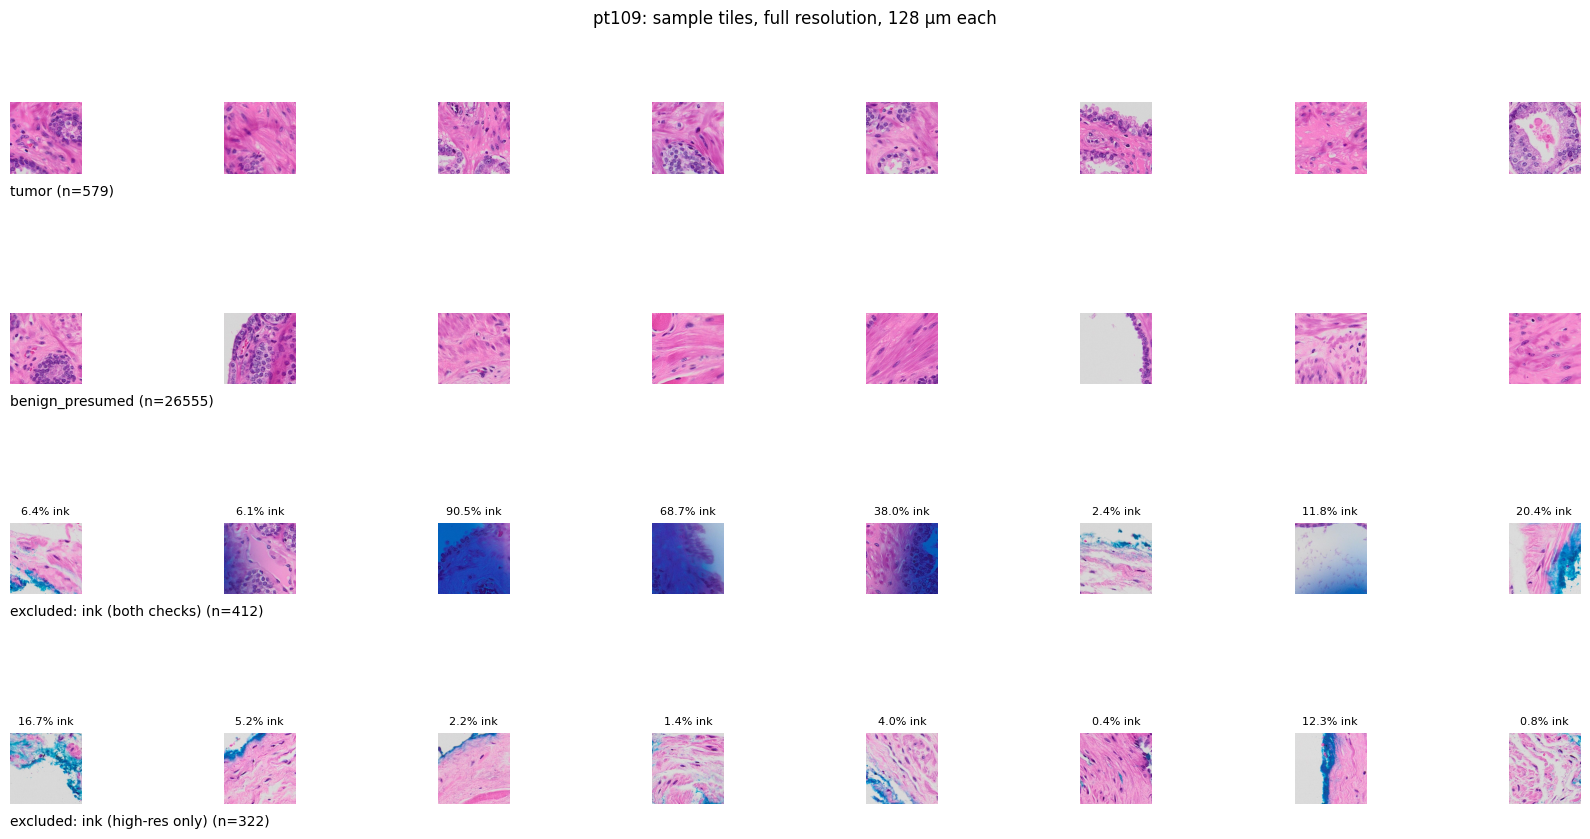

In [9]:
def show_groups(pt, t, n=8):
    groups = {'tumor': t[t.label == 'tumor'],
              'benign_presumed': t[t.label == 'benign_presumed'],
              'excluded: ink (both checks)': t[t.ink_thumb & t.ink_hires],
              'excluded: ink (high-res only)': t[~t.ink_thumb & t.ink_hires]}
    if pt in PENDING:
        groups['pending (not labeled)'] = t[t.label == 'pending']
    if (t.label == 'excluded_unreadable').any():
        groups['excluded: unreadable (white = damaged data)'] = t[t.label == 'excluded_unreadable']
    reader = SlideReader(TIF_FILES[pt], level=0)
    fig, axes = plt.subplots(len(groups), n, figsize=(2 * n, 2.2 * len(groups)), squeeze=False)
    for r, (name, g) in enumerate(groups.items()):
        pick = g.sample(min(n, len(g)), random_state=0) if len(g) else g
        for c in range(n):
            ax = axes[r, c]; ax.axis('off')
            if c < len(pick):
                row = pick.iloc[c]
                ax.imshow(reader.read_level0_box(int(row.x0), int(row.y0), int(row.tile_px)))
                if 'ink' in name: ax.set_title(f'{100 * row.ink_frac_hires:.1f}% ink', fontsize=8)
        axes[r, 0].text(0, -0.15, f'{name} (n={len(g)})', transform=axes[r, 0].transAxes, fontsize=10, va='top')
    reader.close()
    fig.suptitle(f'{pt}: sample tiles, full resolution, 128 µm each', y=1.0)
    plt.tight_layout(); save_fig(f'tiles_{pt}'); plt.show()

for pt, t in labels.items():
    show_groups(pt, t)

## 6. Label maps
Each square is one tile. Red = tumor, green = benign, black = excluded for ink, light gray = buffer around tumor, orange = uncertain or pending, purple = unreadable.
Shown next to the EDA thumbnail for comparison.

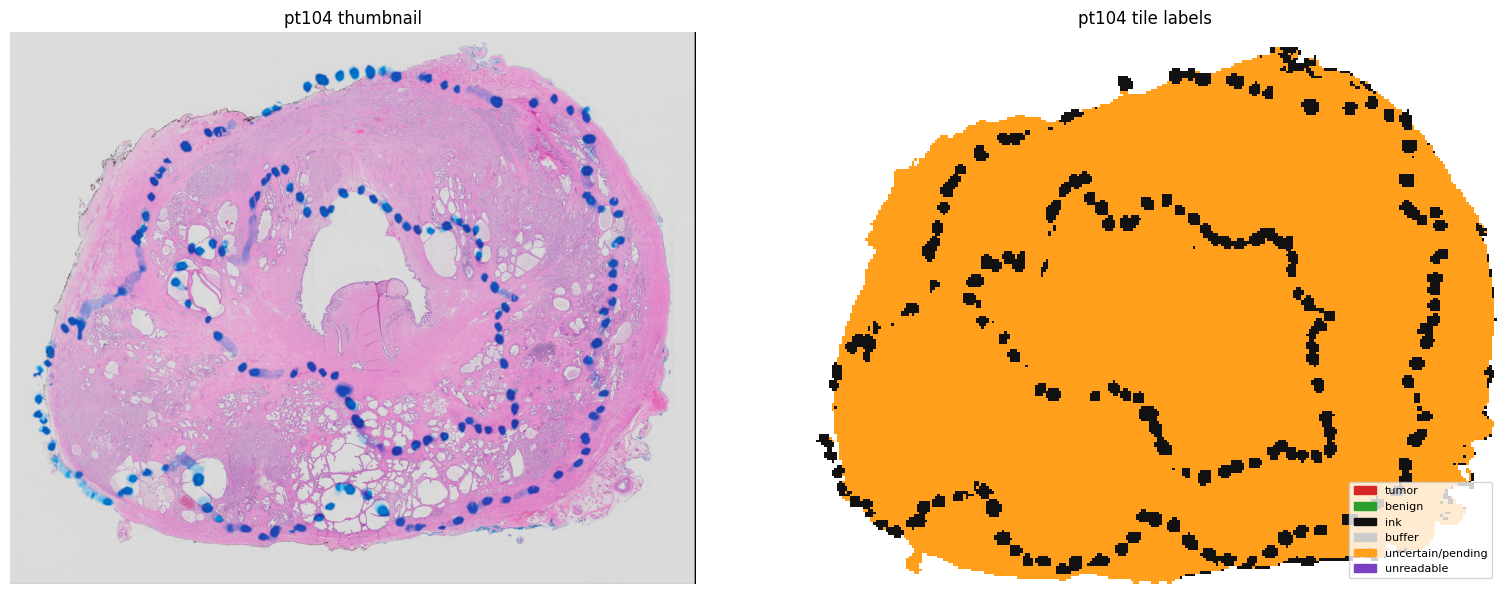

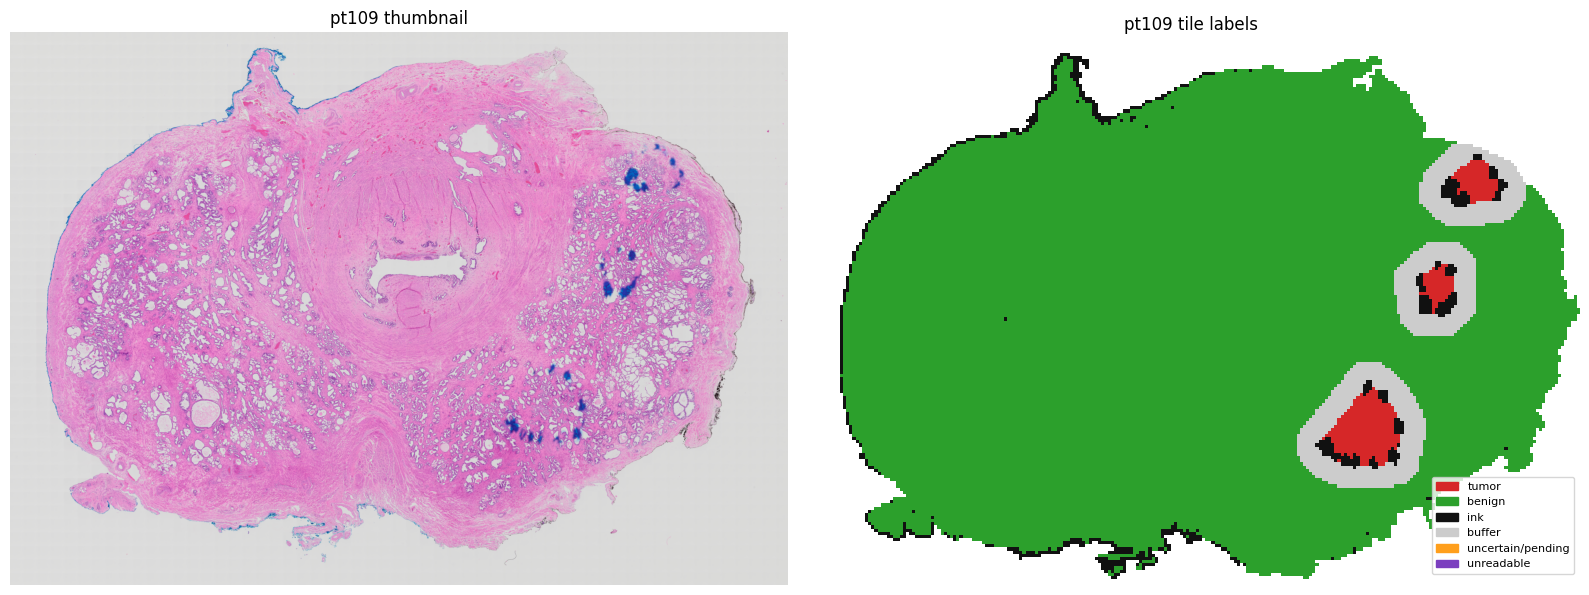

In [8]:
cmap = ListedColormap(COLORS)
for pt, t in labels.items():
    grid = np.full((t.gy.max() + 1, t.gx.max() + 1), np.nan)
    grid[t.gy, t.gx] = t.label.map({l: i for i, l in enumerate(LABELS)}).values
    thumb_path = os.path.join(EDA_DIR, f'{pt}_thumb.png')
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    if os.path.exists(thumb_path):
        axes[0].imshow(Image.open(thumb_path))
    axes[0].set_title(f'{pt} thumbnail'); axes[0].axis('off')
    axes[1].imshow(grid, cmap=cmap, vmin=-0.5, vmax=len(LABELS) - 0.5, interpolation='nearest')
    axes[1].set_title(f'{pt} tile labels'); axes[1].axis('off')
    handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in COLORS[:5] + COLORS[6:]]
    axes[1].legend(handles, ['tumor', 'benign', 'ink', 'buffer', 'uncertain/pending', 'unreadable'], loc='lower right', fontsize=8)
    plt.tight_layout(); save_fig(f'label_map_{pt}'); plt.show()

## 7. Optional: export tile images
Writes sample tiles as JPEG files, resized to 256 px (0.5 µm/px), into `tiles_v1/images/{pt}/{label}/`.
Useful for looking through tiles or sharing with the lab. Set `EXPORT_MAX` to `None` to write all tumor and benign tiles
(this is large: tens of thousands of files).

In [ ]:
EXPORT = False
EXPORT_MAX = 200           # per slide and label
EXPORT_LABELS = ['tumor', 'benign_presumed']

if EXPORT:
    for pt, t in labels.items():
        reader = SlideReader(TIF_FILES[pt], level=0)
        for lab in EXPORT_LABELS:
            g = t[t.label == lab]
            if EXPORT_MAX is not None and len(g) > EXPORT_MAX:
                g = g.sample(EXPORT_MAX, random_state=0)
            d = os.path.join(OUT_DIR, 'images', pt, lab); os.makedirs(d, exist_ok=True)
            for r in g.sort_values(['y0', 'x0']).itertuples():
                im = reader.read_level0_box(int(r.x0), int(r.y0), int(r.tile_px))
                Image.fromarray(im).resize((256, 256), Image.BILINEAR).save(os.path.join(d, f'{r.x0}_{r.y0}.jpg'), quality=92)
            print(f'{pt} {lab}: {len(g)} tiles written')
        reader.close()